# 11 · SWLDA 校准预算：Train 留出验证与 flash ROC-AUC

**本 notebook 已替换旧的 Static 结果。** 旧 Static 实验及预处理输出已删除；当前实验不读取任何 Test 文件。

每名被试的 SE003 Train 共 18 个字符，按原冻结顺序将**前 12 个作为校准池，最后 6 个固定留作验证**。因此 k=0…12，不能继续到 18，否则会用到验证字符。SE001、SE002 的全部 Train 可作为历史数据；通道预先固定为 16 个，使用既有 256 维特征和 A 基础故障策略。标准化和 SWLDA 特征筛选仅使用相应预算的训练 epoch。

四条曲线：仅当前、历史 S1+S2＋当前、仅历史 S1＋当前、仅历史 S2＋当前。后三者分别使用 36、18、18 个历史字符，再加当前前 k 个字符。仅当前 k=0 无模型，指标保留缺失。数据充分参考最多使用历史 36＋当前 12＝48 个字符，不包含验证字符；它不是保证更高的数学上限，也不能与小 k 当成相同当前预算。

主指标为 **flash 级 ROC-AUC，先逐被试计算，再对被试取宏平均**。不混合不同模型的原始分数计算一个总体 AUC。所有方案和 k 复用相同的验证 flash 及固定质量掩码。字符准确率仅为辅助结果。

flash 较多能提供更细的指标变化，但相邻 epoch 重叠、同一字符内也有关联，不能把它们当成独立样本计算置信度。计数来自实际 flash 清单，不假定每字符固定有 12×12 次 flash。除 ROC-AUC 外，另报告经训练内概率校准后的类别加权 log-loss；不把 SWLDA 原始线性分数直接当概率。


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'configs/swlda_calibration_budget.json').exists())
OUT = ROOT / 'outputs/swlda_calibration_budget_train_validation_v1'
if not (OUT / 'completion.json').exists():
    raise FileNotFoundError('请先运行 scripts/run_swlda_calibration_budget.py。')
overall = pd.read_csv(OUT / 'overall_results.csv')
subjects = pd.read_csv(OUT / 'subject_results.csv')
LOSS_OUT = OUT / 'weighted_logloss'
has_logloss = (LOSS_OUT / 'completion.json').exists()
if has_logloss:
    overall = overall.merge(pd.read_csv(LOSS_OUT / 'overall_metrics.csv')[
        ['scheme', 'k', 'macro_weighted_log_loss', 'sd_subject_weighted_log_loss']],
        on=['scheme', 'k'], validate='one_to_one')
    subjects = subjects.merge(pd.read_csv(LOSS_OUT / 'subject_metrics.csv')[
        ['subject_id', 'scheme', 'k', 'weighted_log_loss', 'probability_calibration']],
        on=['subject_id', 'scheme', 'k'], validate='one_to_one')
display(pd.Series(json.loads((OUT / 'completion.json').read_text())).to_frame('run'))


,run
subjects,"[F_03, F_05, F_06, F_07, F_08, F_20, F_21, F_2..."
k_values,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
models_fitted,560
endpoint_checks,50
used_test,False
primary_metric,macro_subject_flash_roc_auc
used_gpu,False
source_inputs_unchanged,True
current_validation_characters_never_used_for_fitting,True


## 主结果：flash 级 ROC-AUC

不同 k 都在最后 6 个字符对应的相同 flash 上评估。没有模型时不将 AUC 记成 0。先列 10 人的 2×5 小图和最后的宏平均面板，AUC 小图统一纵轴 0.4–1.0；宏平均阴影按被试 bootstrap 10,000 次，只画主设计和仅当前两层（透明度 15%）。配色（全报告统一）：仅当前为灰色细线，历史 S1+S2+当前（主设计）为最粗的蓝色 `#0072B2`，历史 S1+当前为橙色 `#E69F00`，历史 S2+当前为蓝绿色 `#009E73`；仅历史与全部训练数据参考线为深灰虚线/点线，直接在右侧标注，不放进图例。之后保留宏平均总览和放大图，便于检查细小差异。


,scheme,k,available_models,macro_flash_roc_auc,sd_subject_flash_roc_auc,validation_flashes,scored_validation_flashes
0,current_only,0,0,NaN,NaN,7560,0
1,current_only,1,10,0.655916,0.125833,7560,7340
2,current_only,2,10,0.720341,0.152481,7560,7340
3,current_only,3,10,0.748888,0.139952,7560,7340
4,current_only,4,10,0.768968,0.150741,7560,7340
5,current_only,5,10,0.780313,0.152385,7560,7340
6,current_only,6,10,0.794682,0.159129,7560,7340
7,current_only,7,10,0.801458,0.160932,7560,7340
8,current_only,8,10,0.806192,0.161421,7560,7340
9,current_only,9,10,0.816801,0.151498,7560,7340


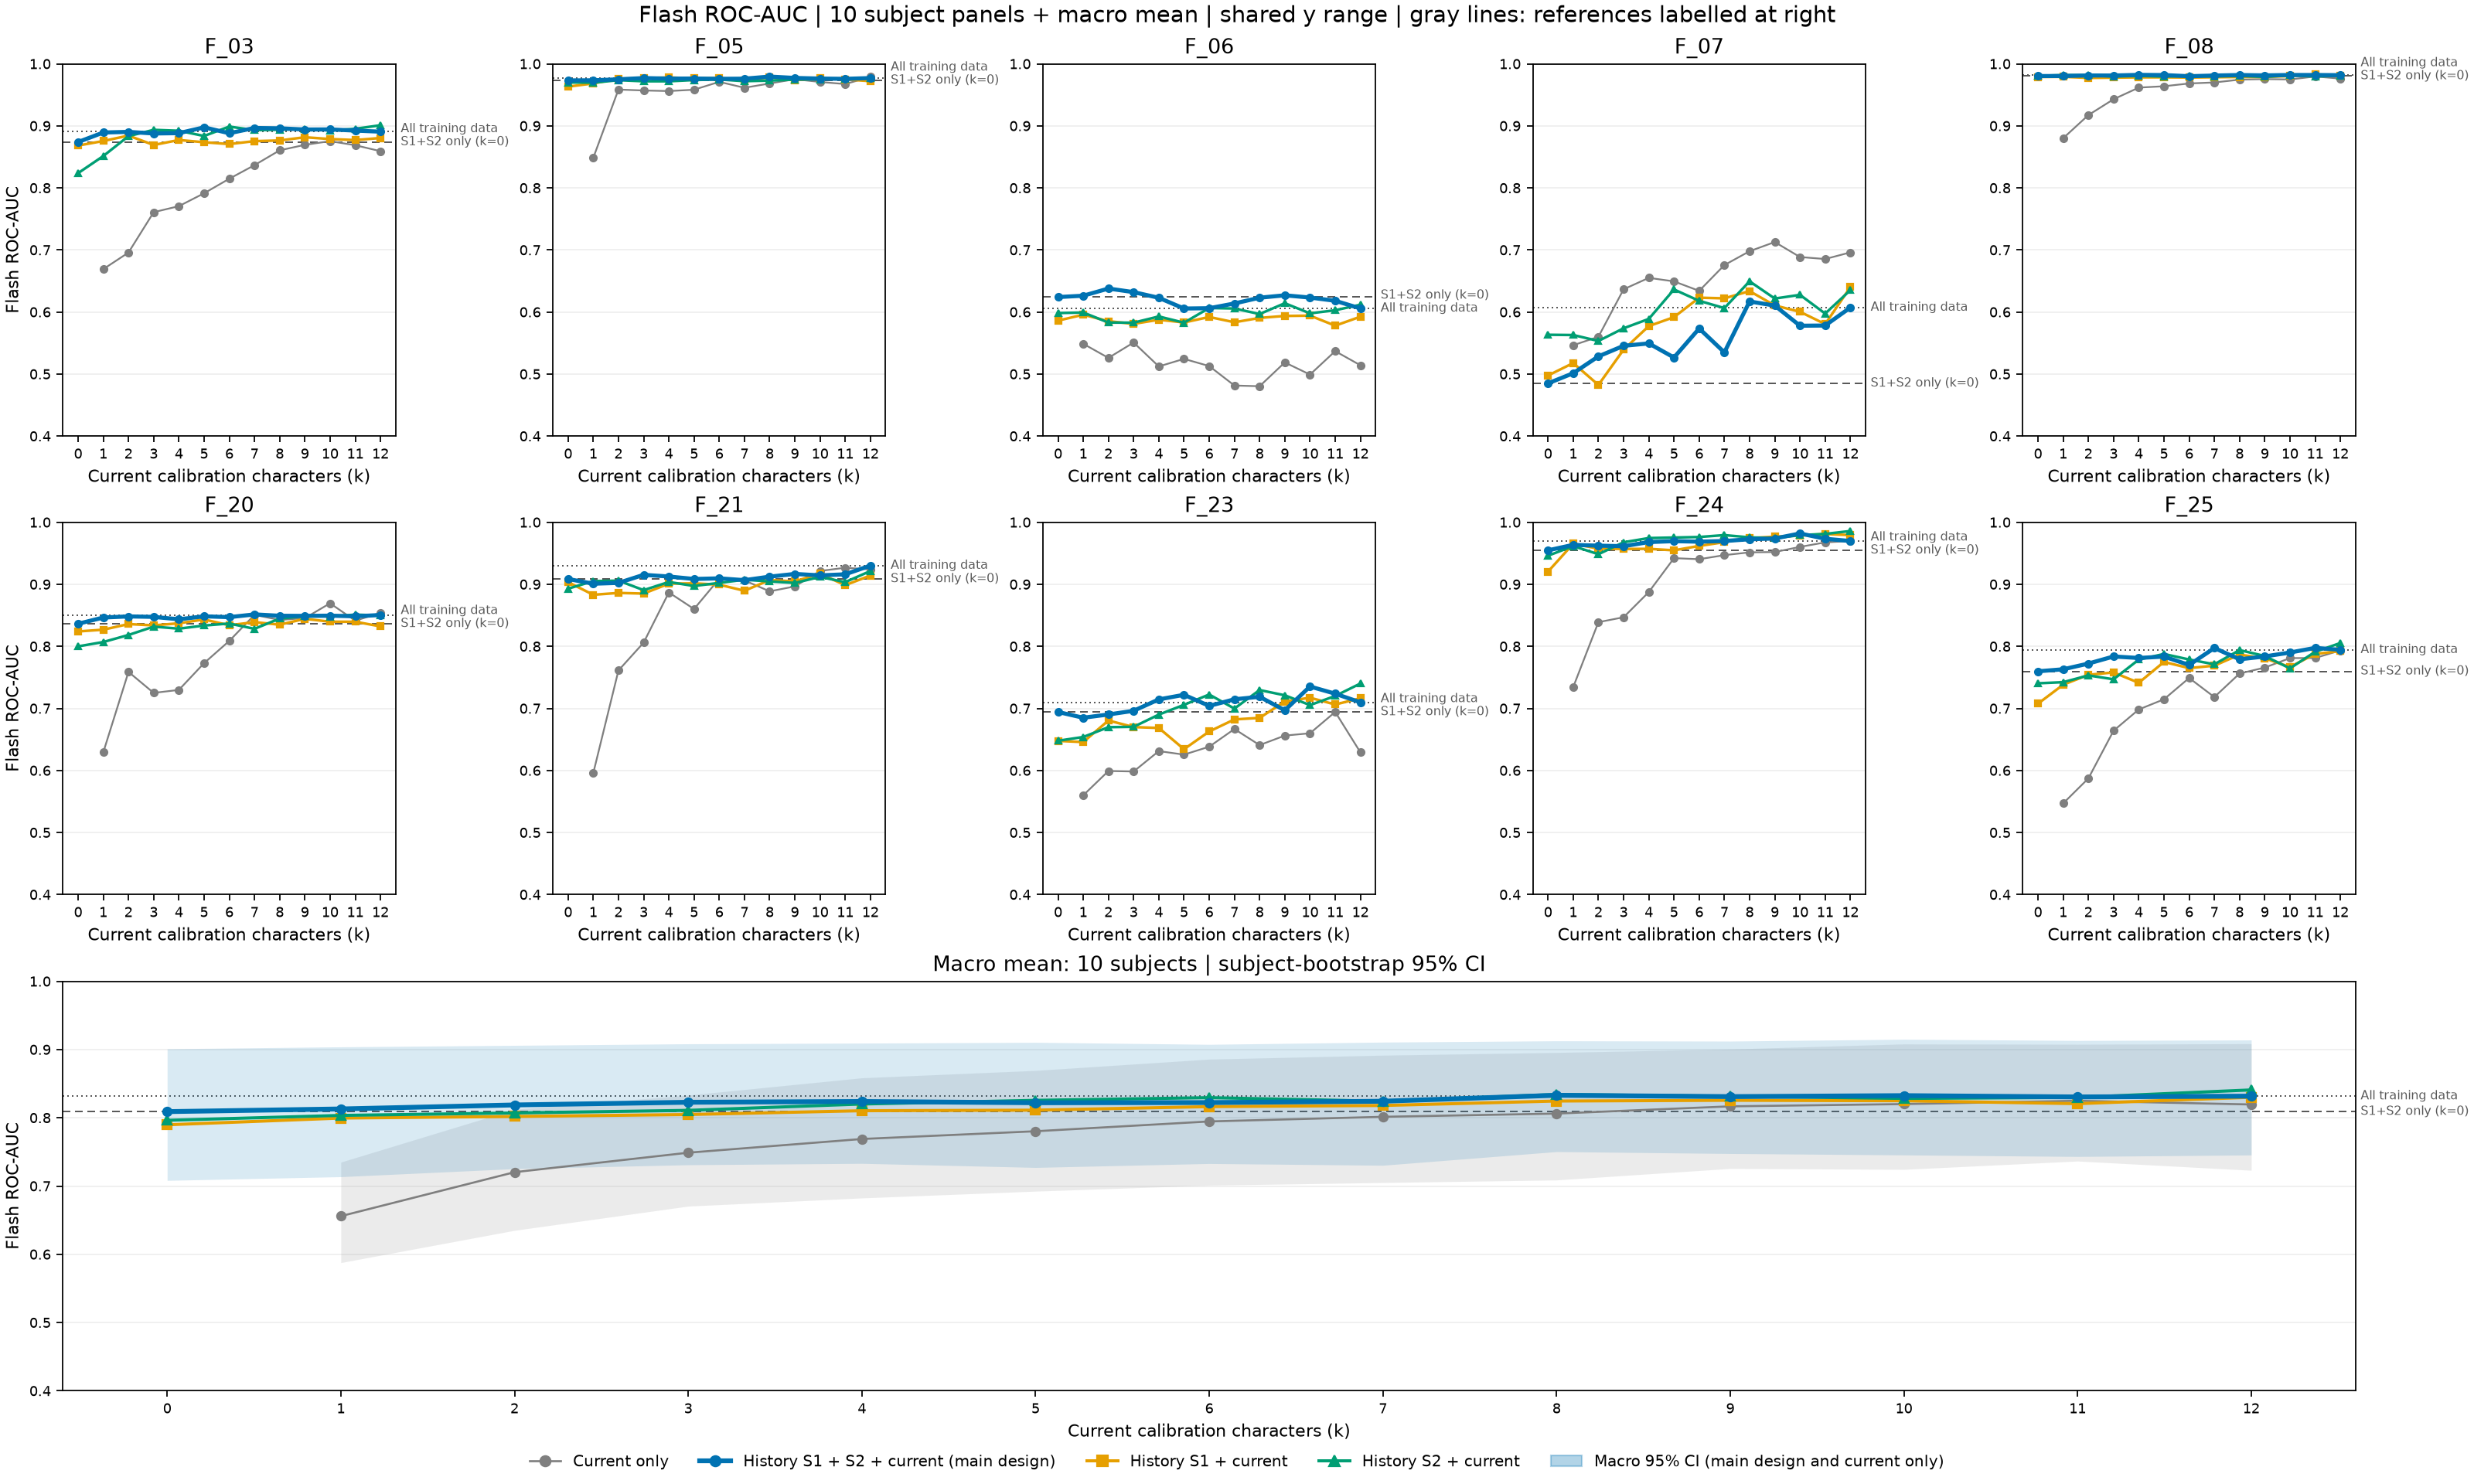

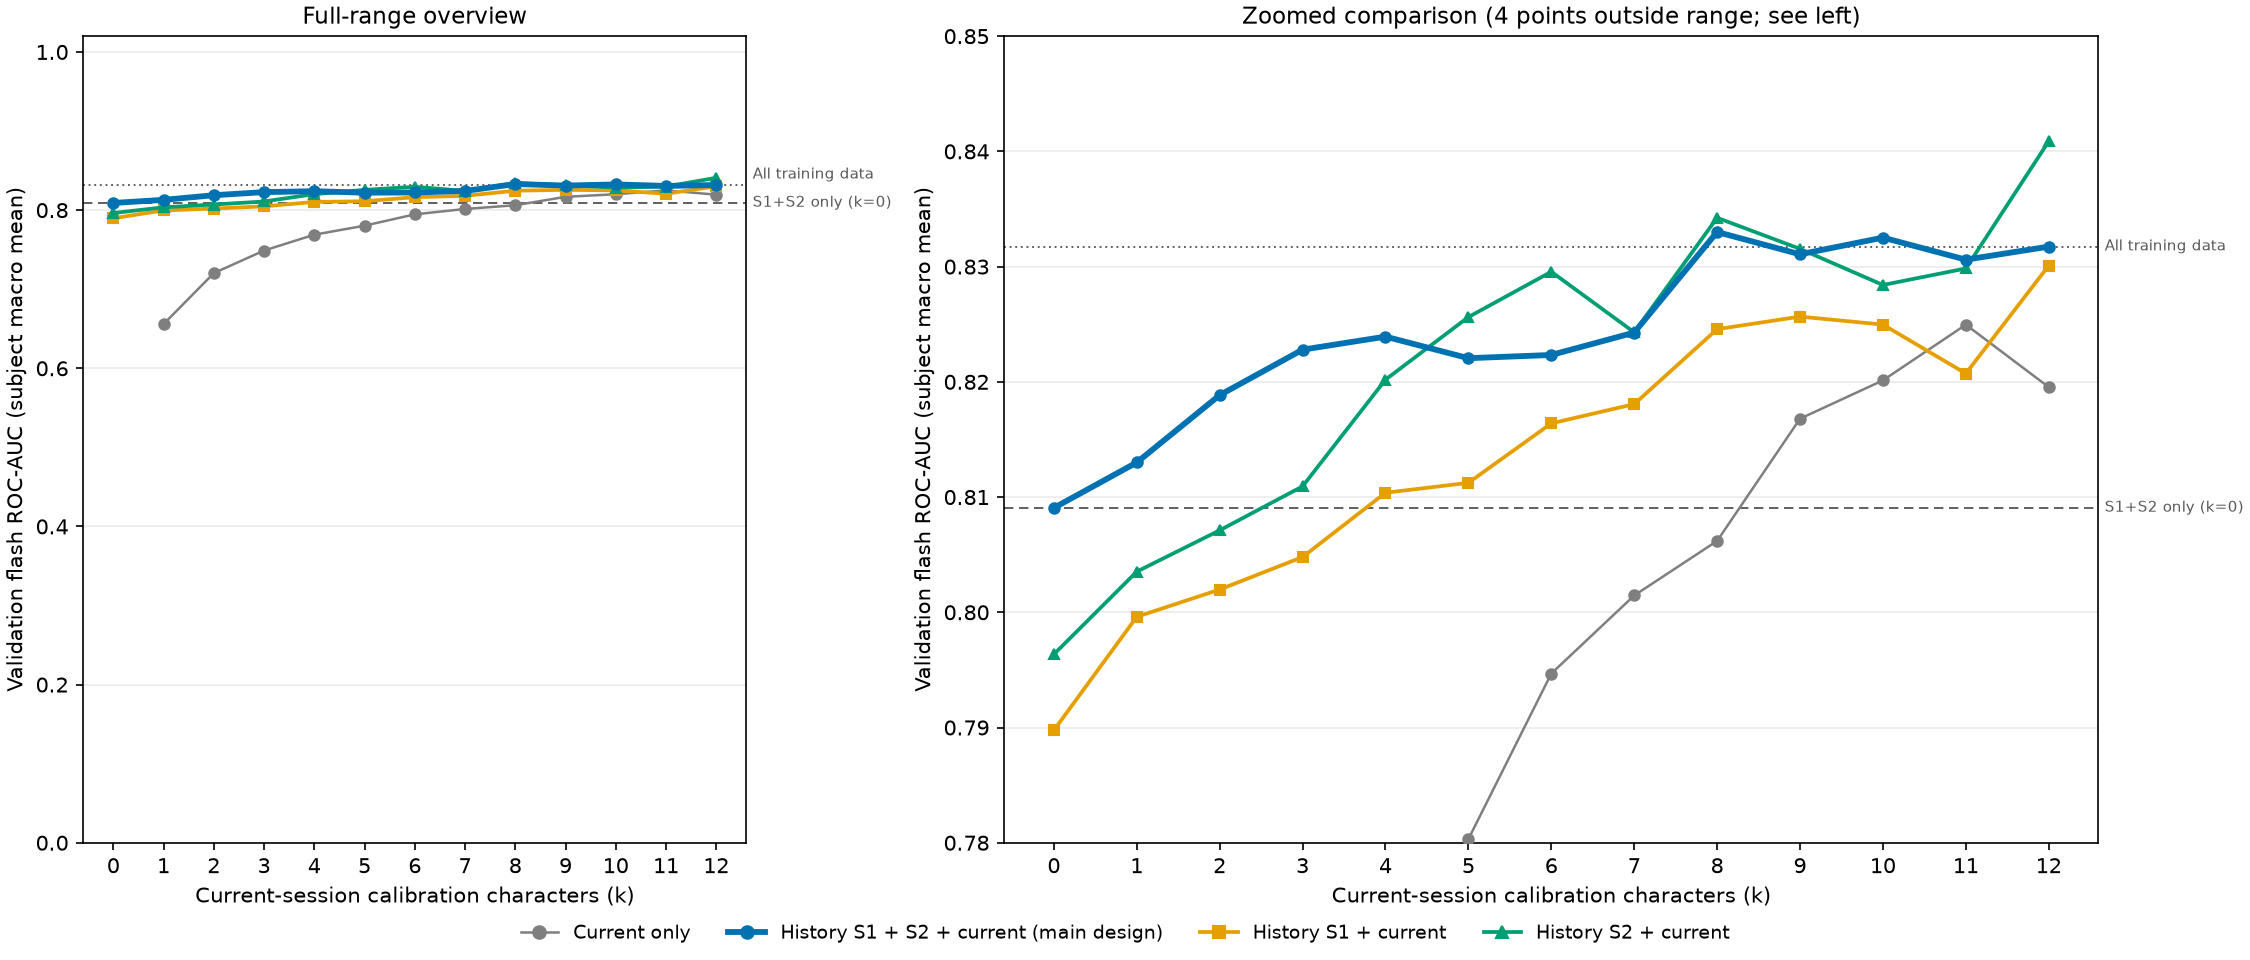

In [2]:
display(overall[['scheme', 'k', 'available_models', 'macro_flash_roc_auc',
                 'sd_subject_flash_roc_auc', 'validation_flashes', 'scored_validation_flashes']])
display(Image(filename=str(OUT / 'auc_small_multiples.png')))
display(Image(filename=str(OUT / 'calibration_curves.png')))


## 类别加权 flash log-loss：越低越好

本批实际保留 815 个靶标、6,525 个非靶标，接近 1:8；不按假定 sequence 的 1:5 比例写死权重。每名被试分别计算：

`weighted log-loss = -0.5 × mean_target(log p) - 0.5 × mean_nontarget(log(1-p))`

因此两类各占一半权重，再对被试宏平均。验证集的类计数只定义评价指标，不拿来训练模型。概率截断为 [1e-7, 1-1e-7]，常数预测 p=0.5 的参考损失为 ln(2)≈0.693。

SWLDA 的概率层是 Platt sigmoid：在当前模型允许的训练字符内做最多三折、按完整字符分组的交叉拟合，用未参与该折拟合的训练 flash 分数拟合 sigmoid。不会把重叠 flash 分散到不同折；不会用验证字符拟合概率层。sigmoid 拟合不做类别重加权，保留自然训练先验；加权仅用于 log-loss 评价。原有 SWLDA 分数、AUC 和字符预测不变。

仅当前 k=1 只有一个训练字符，无法按字符交叉拟合，明确回退为训练内分数拟合，并在结果表标记 `training_in_sample_single_character`。这一点的概率层更易过拟合，不能将其解释为独立校准质量。其余点同样不保证在验证集上已完美校准。


,scheme,k,macro_weighted_log_loss,sd_subject_weighted_log_loss
0,current_only,0,NaN,NaN
1,current_only,1,2.471202,0.826197
2,current_only,2,1.009358,0.178725
3,current_only,3,0.927635,0.258016
4,current_only,4,0.890135,0.290675
5,current_only,5,0.845987,0.294082
6,current_only,6,0.819162,0.307321
7,current_only,7,0.822782,0.291472
8,current_only,8,0.796840,0.296364
9,current_only,9,0.776257,0.308766


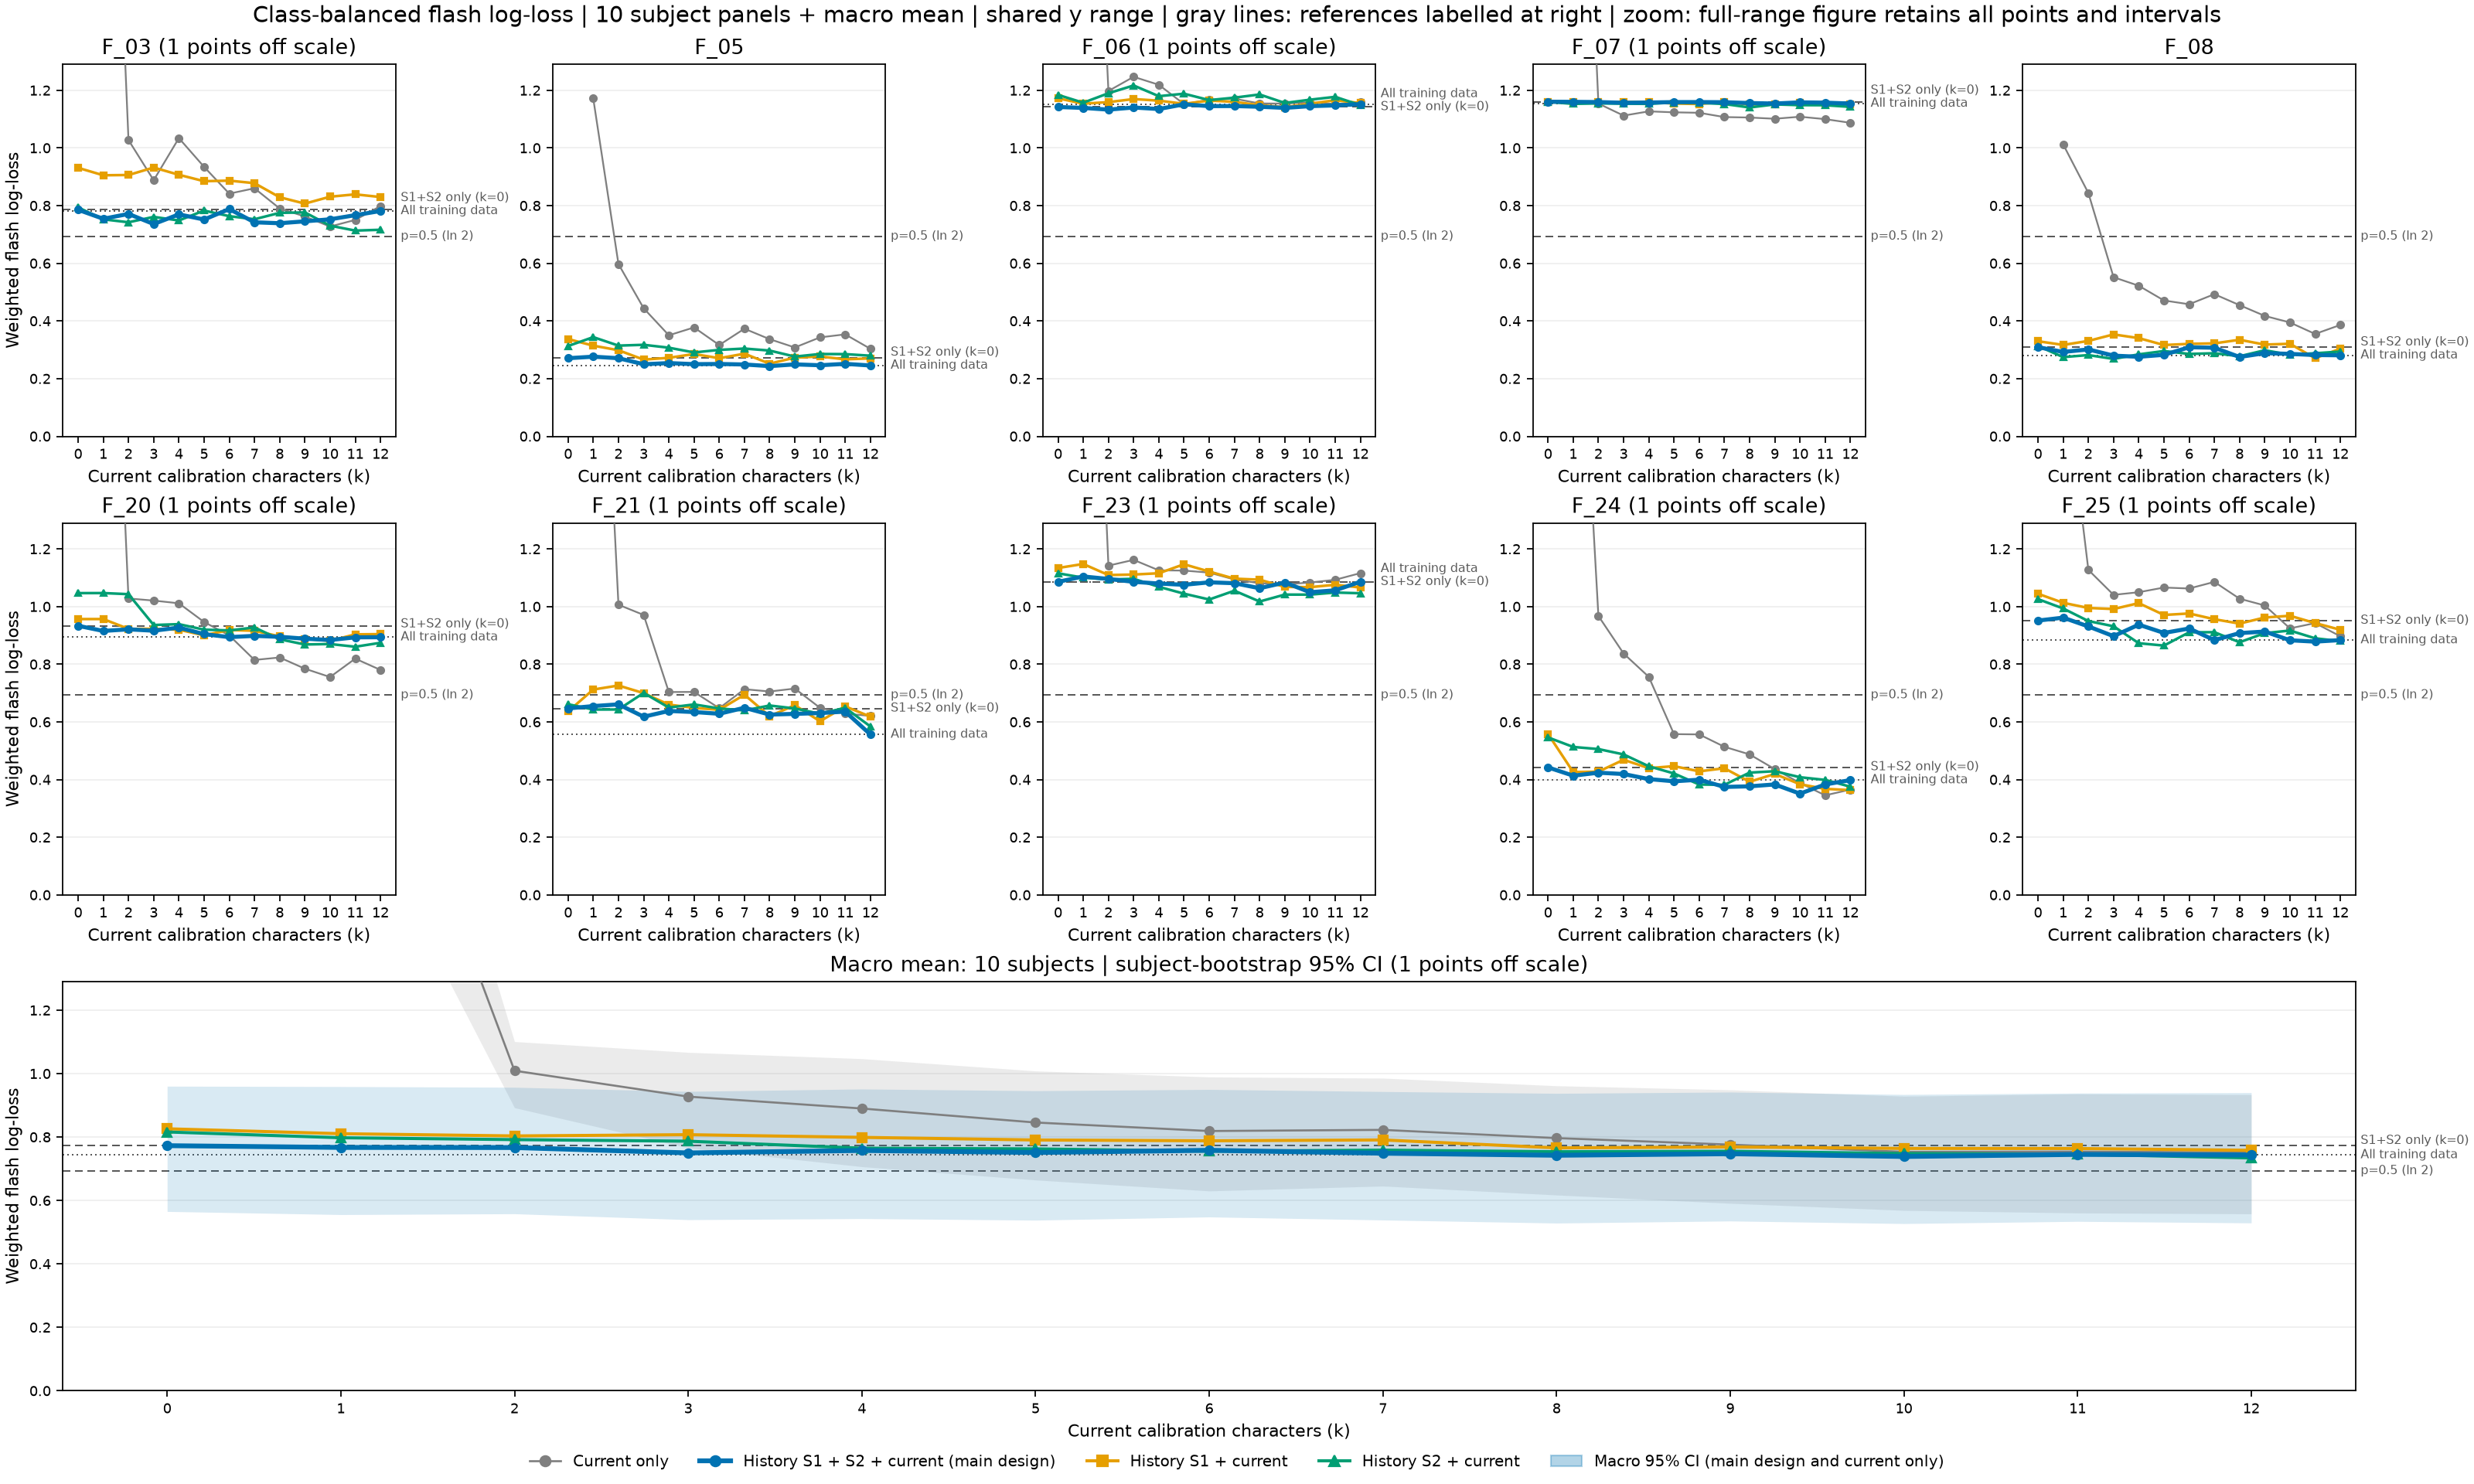

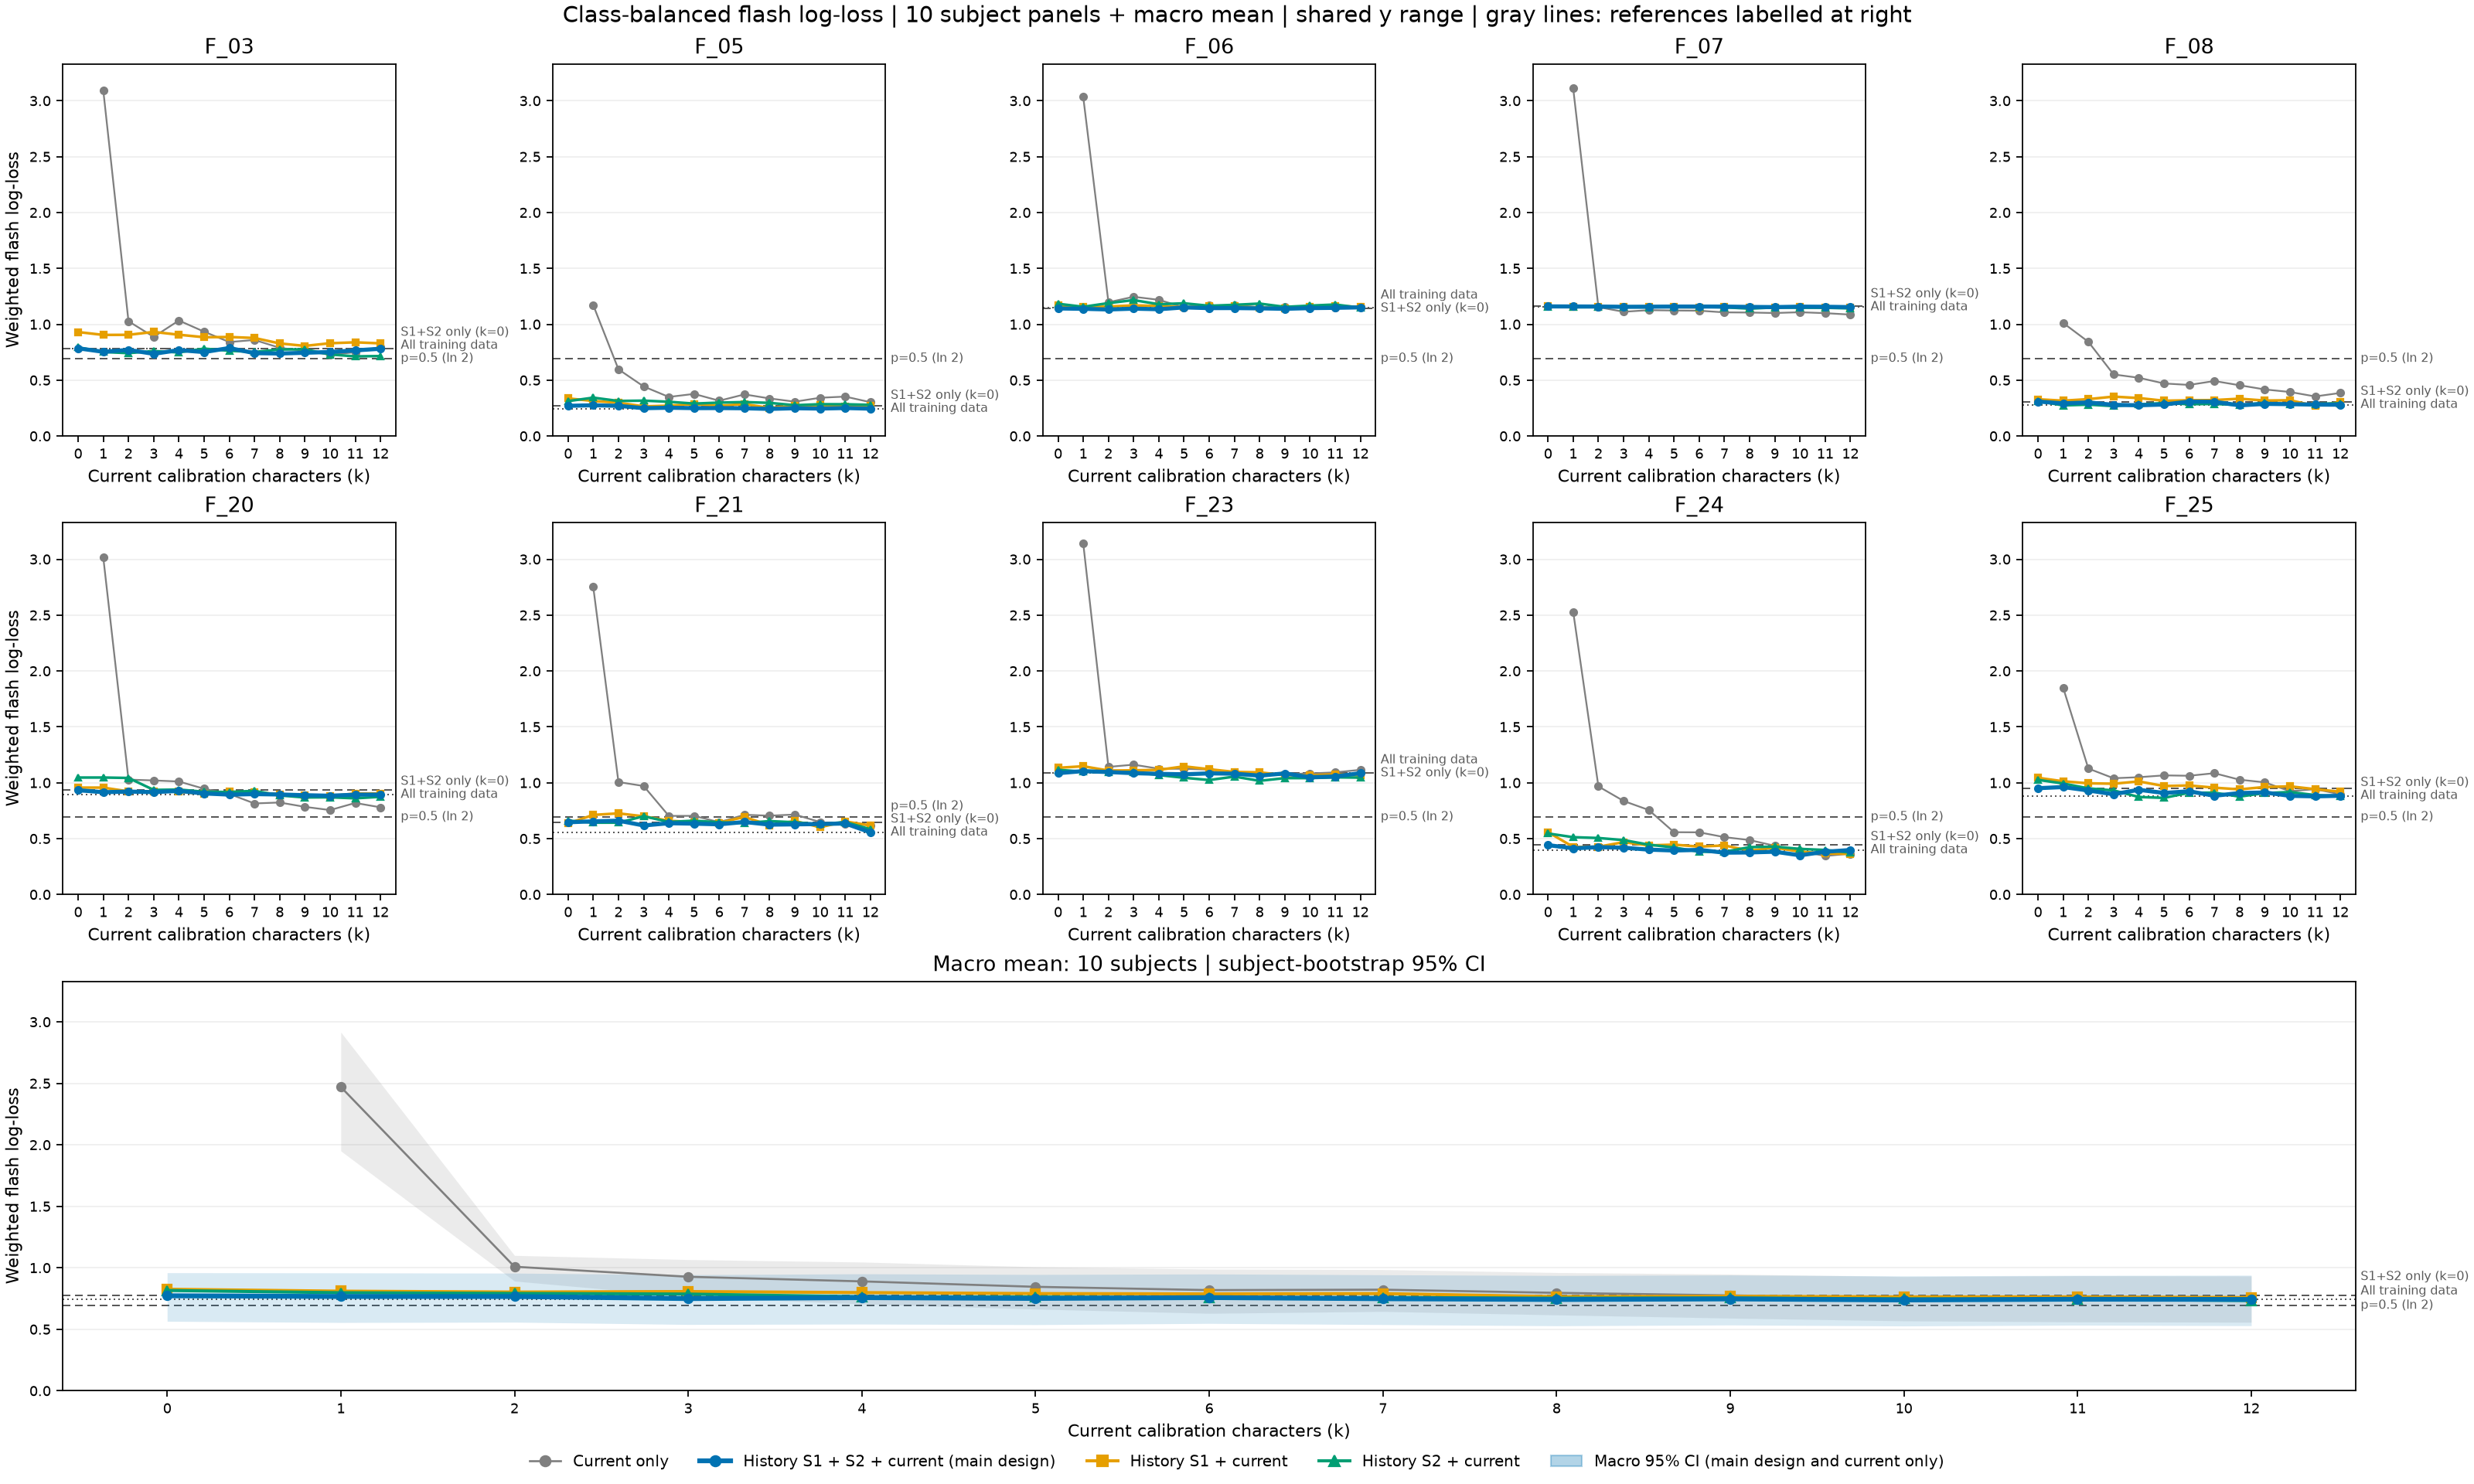

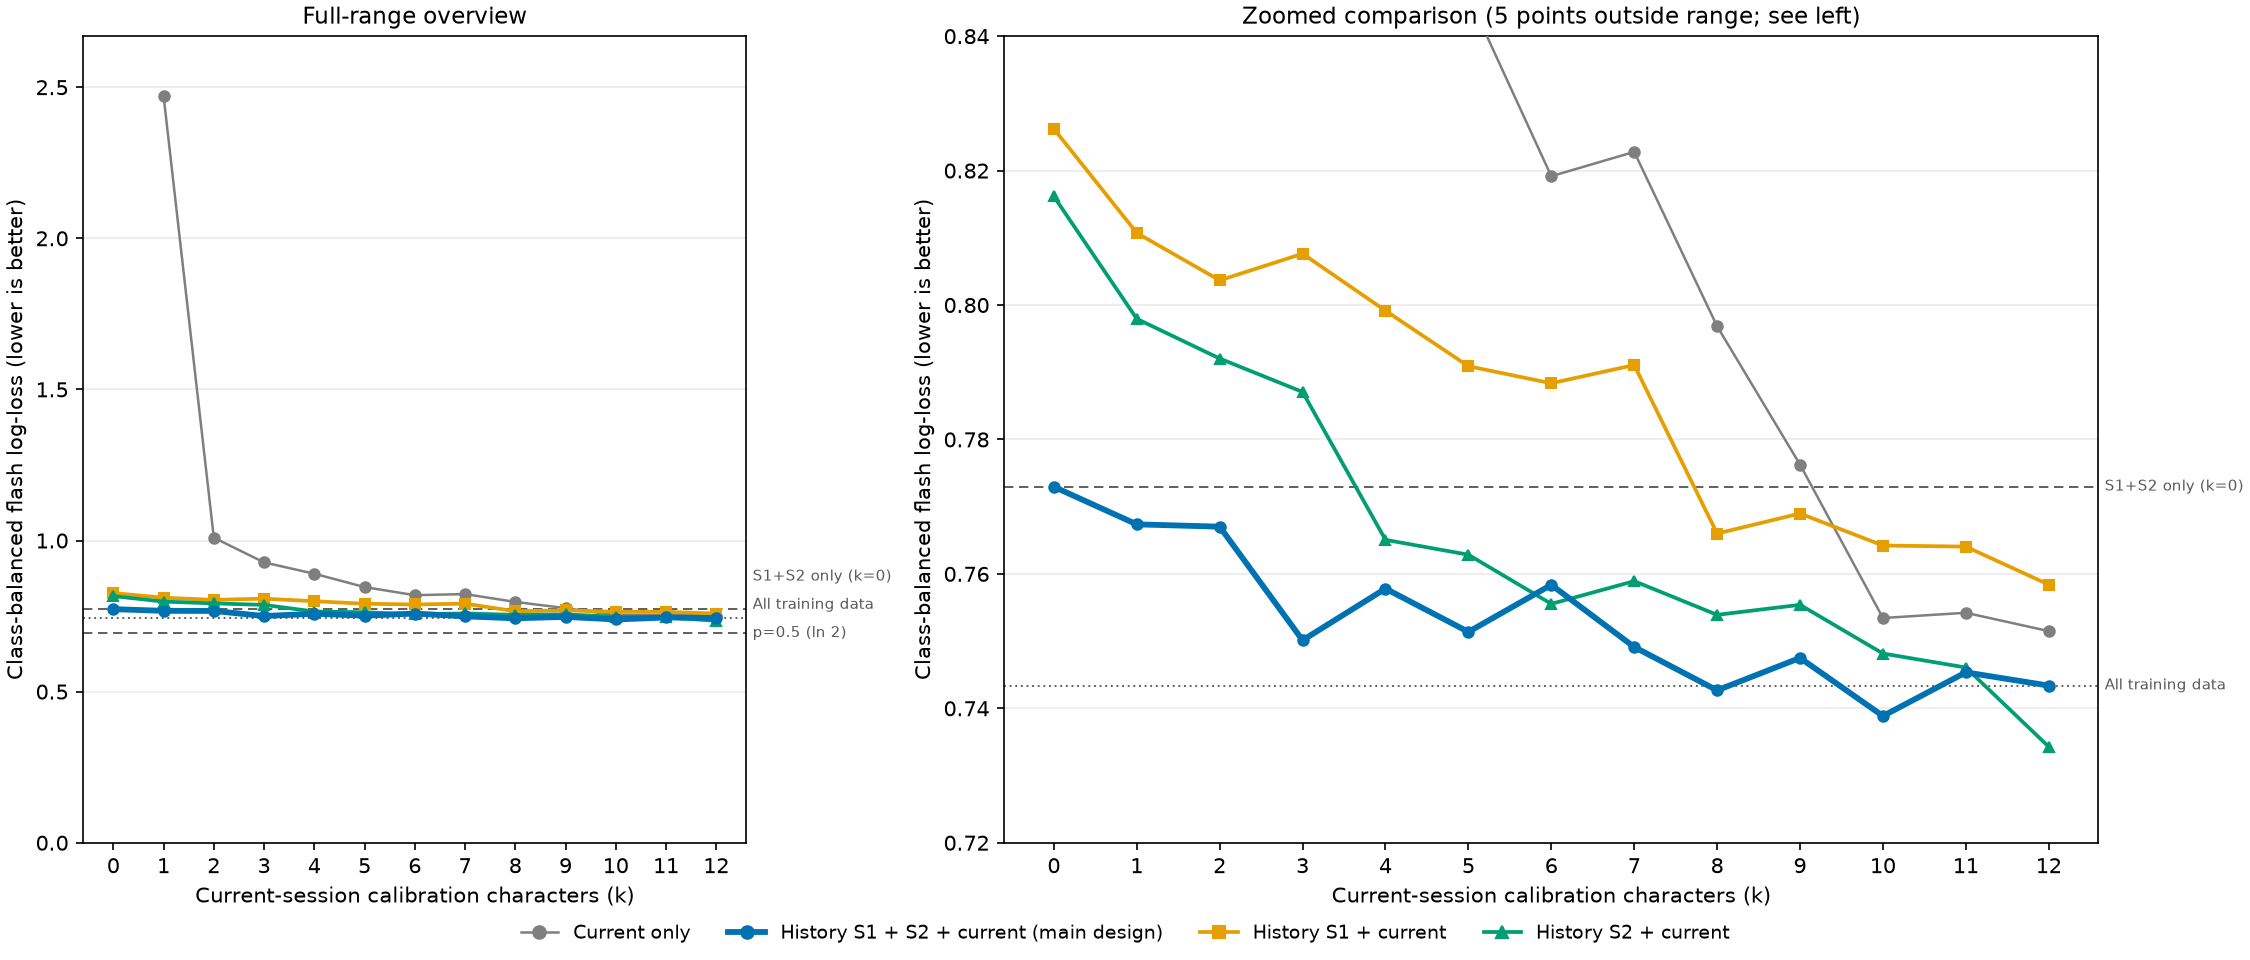

,subject_id,scheme,k,weighted_log_loss,probability_calibration
1,F_03,current_only,1,3.092378,training_in_sample_single_character
58,F_05,current_only,1,1.171716,training_in_sample_single_character
115,F_06,current_only,1,3.034872,training_in_sample_single_character
172,F_07,current_only,1,3.110524,training_in_sample_single_character
229,F_08,current_only,1,1.012492,training_in_sample_single_character
286,F_20,current_only,1,3.015607,training_in_sample_single_character
343,F_21,current_only,1,2.752208,training_in_sample_single_character
400,F_23,current_only,1,3.142213,training_in_sample_single_character
457,F_24,current_only,1,2.529749,training_in_sample_single_character
514,F_25,current_only,1,1.850259,training_in_sample_single_character


In [3]:
if not has_logloss:
    print('请先运行 scripts/add_weighted_logloss.py；本格不会自动拟合概率层。')
else:
    display(overall[['scheme', 'k', 'macro_weighted_log_loss', 'sd_subject_weighted_log_loss']])
    display(Image(filename=str(LOSS_OUT / 'logloss_small_multiples_zoom.png')))
    display(Image(filename=str(LOSS_OUT / 'logloss_small_multiples.png')))
    display(Image(filename=str(LOSS_OUT / 'weighted_logloss_curves.png')))
    display(subjects[subjects.probability_calibration.eq('training_in_sample_single_character')][
        ['subject_id', 'scheme', 'k', 'weighted_log_loss', 'probability_calibration']])


## 端点与预算检查

仅历史端点与对应历史＋当前曲线 k=0、仅当前最大端点与 k=12、数据充分参考与历史 S1+S2＋当前 k=12，均独立重训核对权重和预测。验证字符不能进入任何一个训练集。


In [4]:
endpoint_names = ['history_only', 'history_se001_only', 'history_se002_only',
                  'current_max_endpoint', 'all_available_reference']
display(overall[overall.scheme.isin(endpoint_names)][
    ['scheme', 'k', 'macro_flash_roc_auc', 'correct_characters', 'validation_characters', 'pooled_accuracy']])
display(pd.read_csv(OUT / 'endpoint_checks.csv'))
display(subjects[subjects.scheme.isin(endpoint_names)].pivot(
    index='subject_id', columns='scheme', values='flash_roc_auc'))


,scheme,k,macro_flash_roc_auc,correct_characters,validation_characters,pooled_accuracy
52,history_only,0,0.809059,46,60,0.766667
53,history_se001_only,0,0.789758,44,60,0.733333
54,history_se002_only,0,0.796351,44,60,0.733333
55,current_max_endpoint,12,0.819540,46,60,0.766667
56,all_available_reference,12,0.831736,49,60,0.816667


,subject_id,endpoint,curve,k,independent_refit_agrees
0,F_03,history_only,history_plus_current,0,True
1,F_03,history_se001_only,history_se001_plus_current,0,True
2,F_03,history_se002_only,history_se002_plus_current,0,True
3,F_03,current_max_endpoint,current_only,12,True
4,F_03,all_available_reference,history_plus_current,12,True
5,F_05,history_only,history_plus_current,0,True
6,F_05,history_se001_only,history_se001_plus_current,0,True
7,F_05,history_se002_only,history_se002_plus_current,0,True
8,F_05,current_max_endpoint,current_only,12,True
9,F_05,all_available_reference,history_plus_current,12,True


scheme,all_available_reference,current_max_endpoint,history_only,history_se001_only,history_se002_only
subject_id,,,,,
F_03,0.890704,0.859244,0.873953,0.868281,0.823814
F_05,0.977069,0.978977,0.973290,0.963246,0.969999
F_06,0.605810,0.514234,0.624102,0.586151,0.598347
F_07,0.607194,0.696113,0.485037,0.497681,0.563332
F_08,0.981756,0.976216,0.980319,0.978825,0.980565
F_20,0.850554,0.854033,0.836413,0.824069,0.800015
F_21,0.930218,0.924111,0.908589,0.903541,0.892973
F_23,0.709754,0.629252,0.694251,0.647685,0.647874
F_24,0.969807,0.969788,0.954796,0.920443,0.946118


## 辅助结果：字符准确率

每名被试验证字符只有 6 个，不用这个离散指标决定 EEGNet 的停止 epoch。此前 Static 上的阈值查询和“达到 81.76% 的 k”不沿用到本划分。


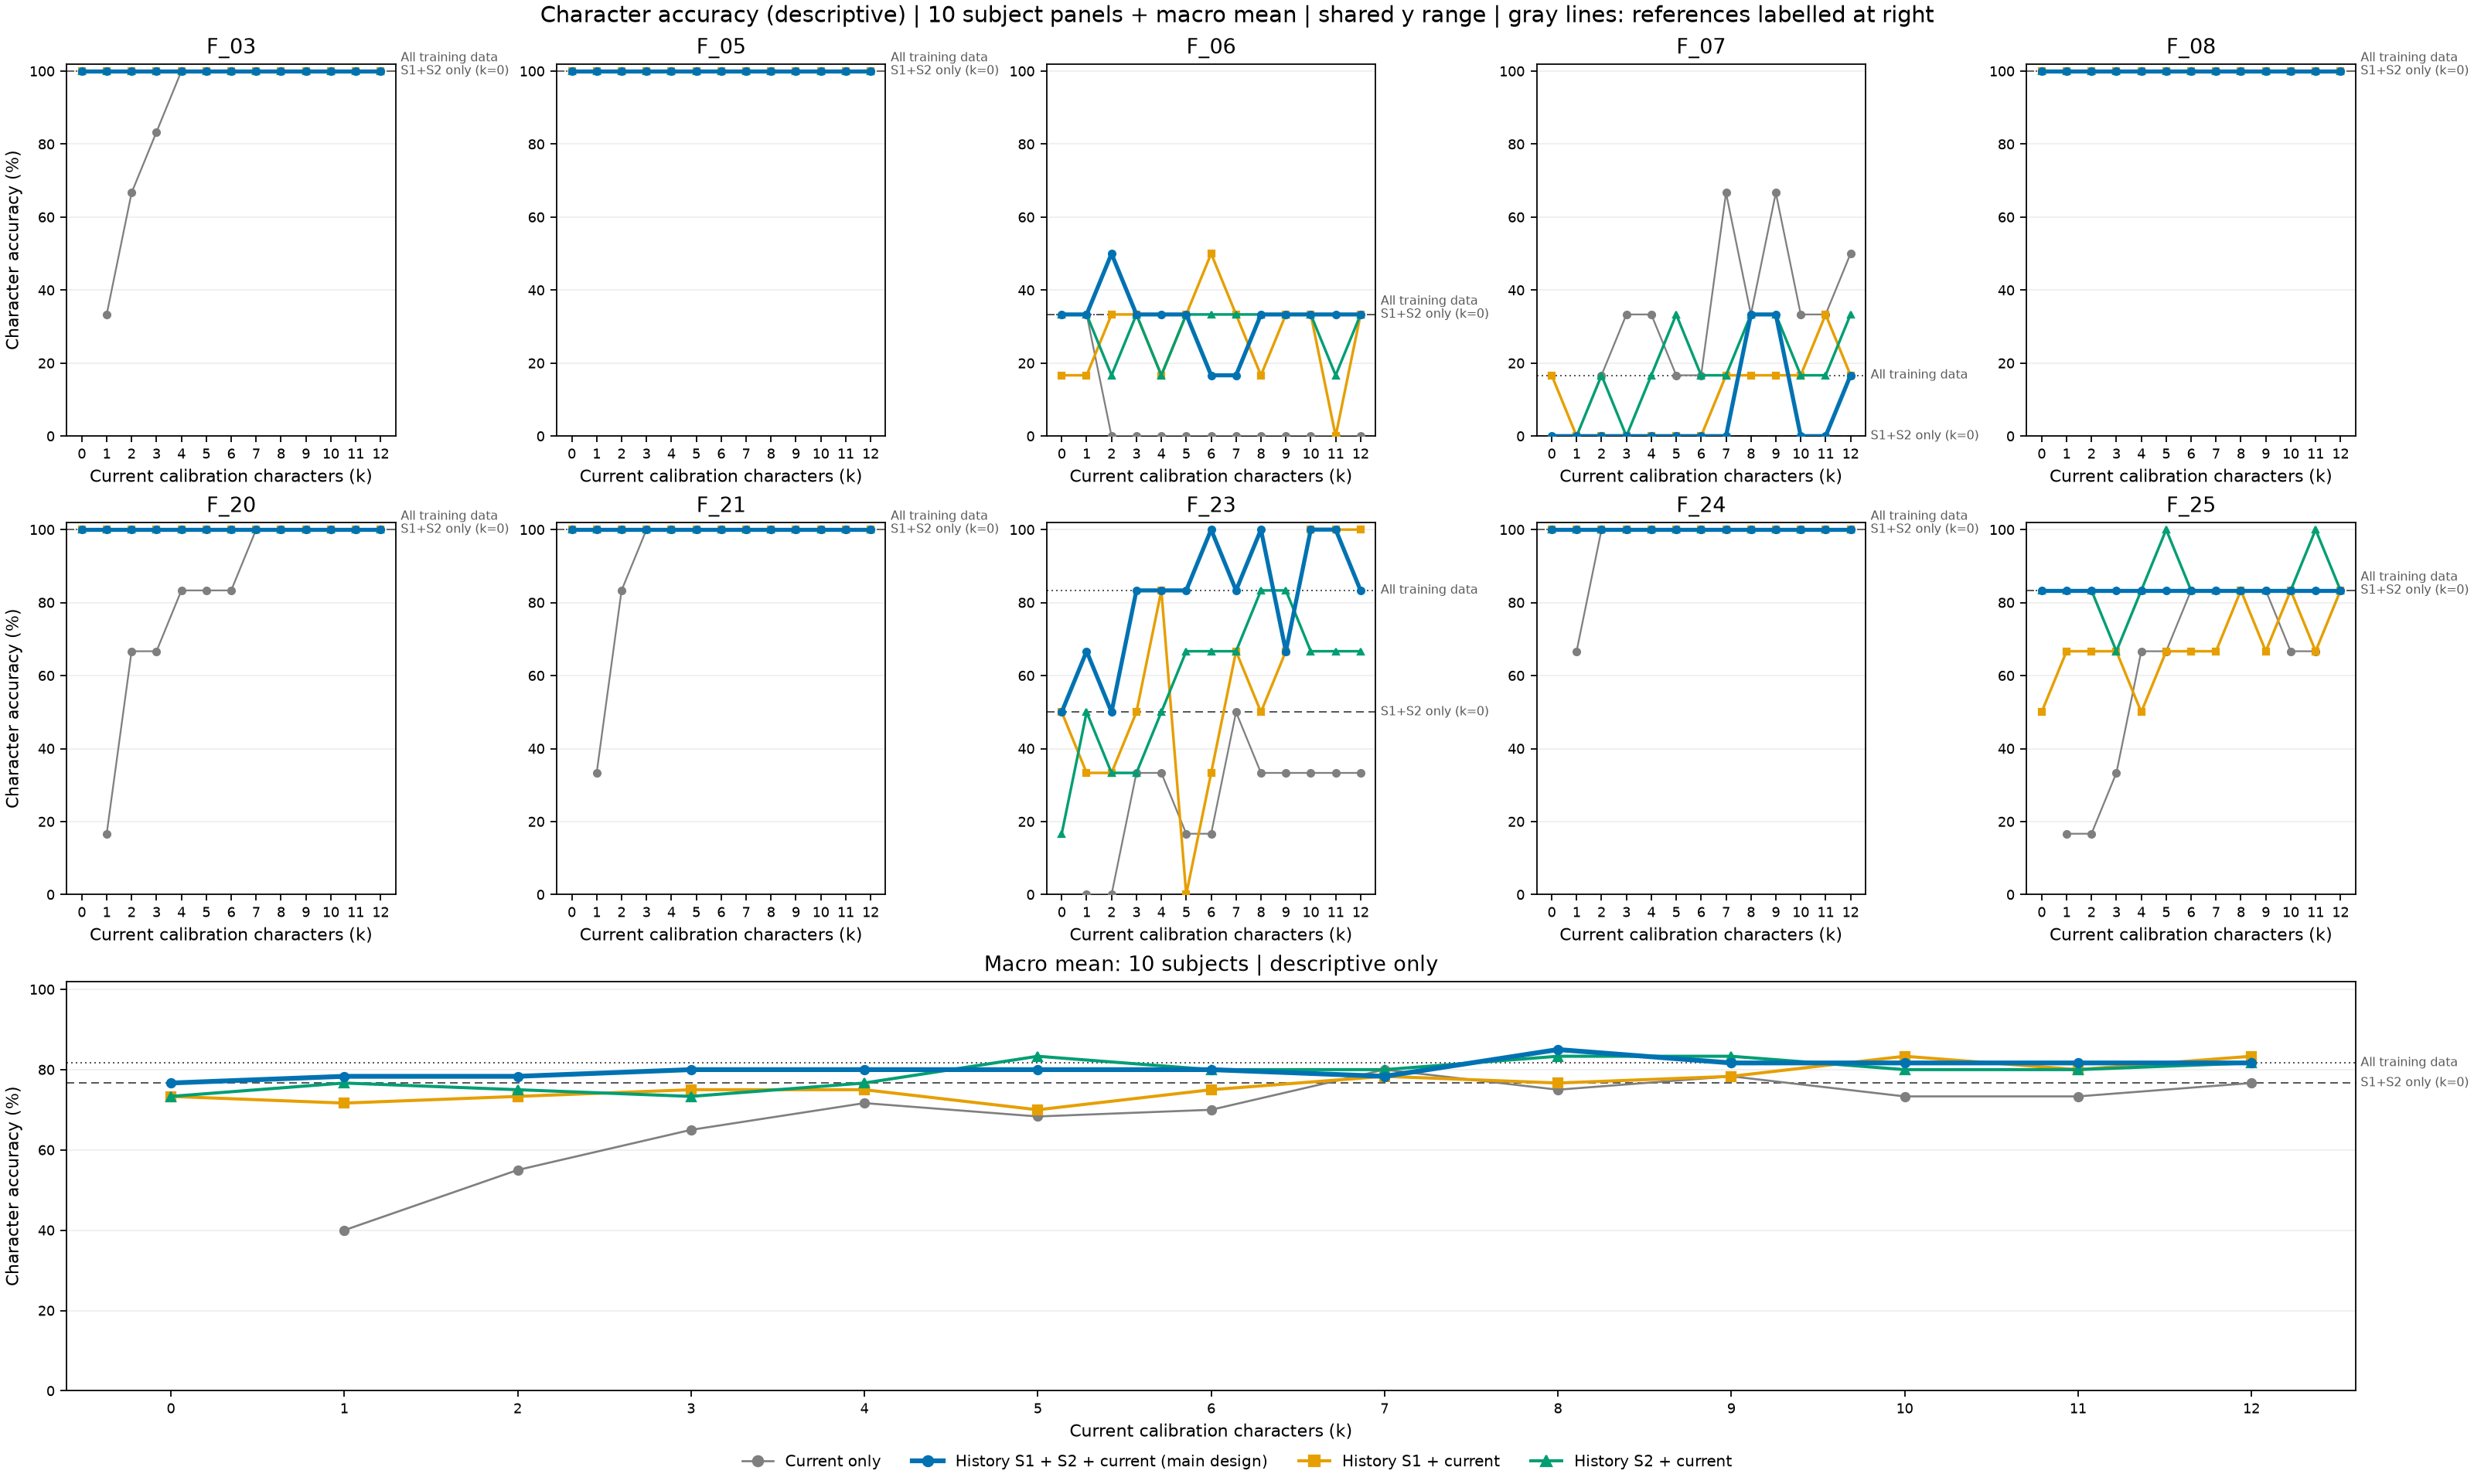

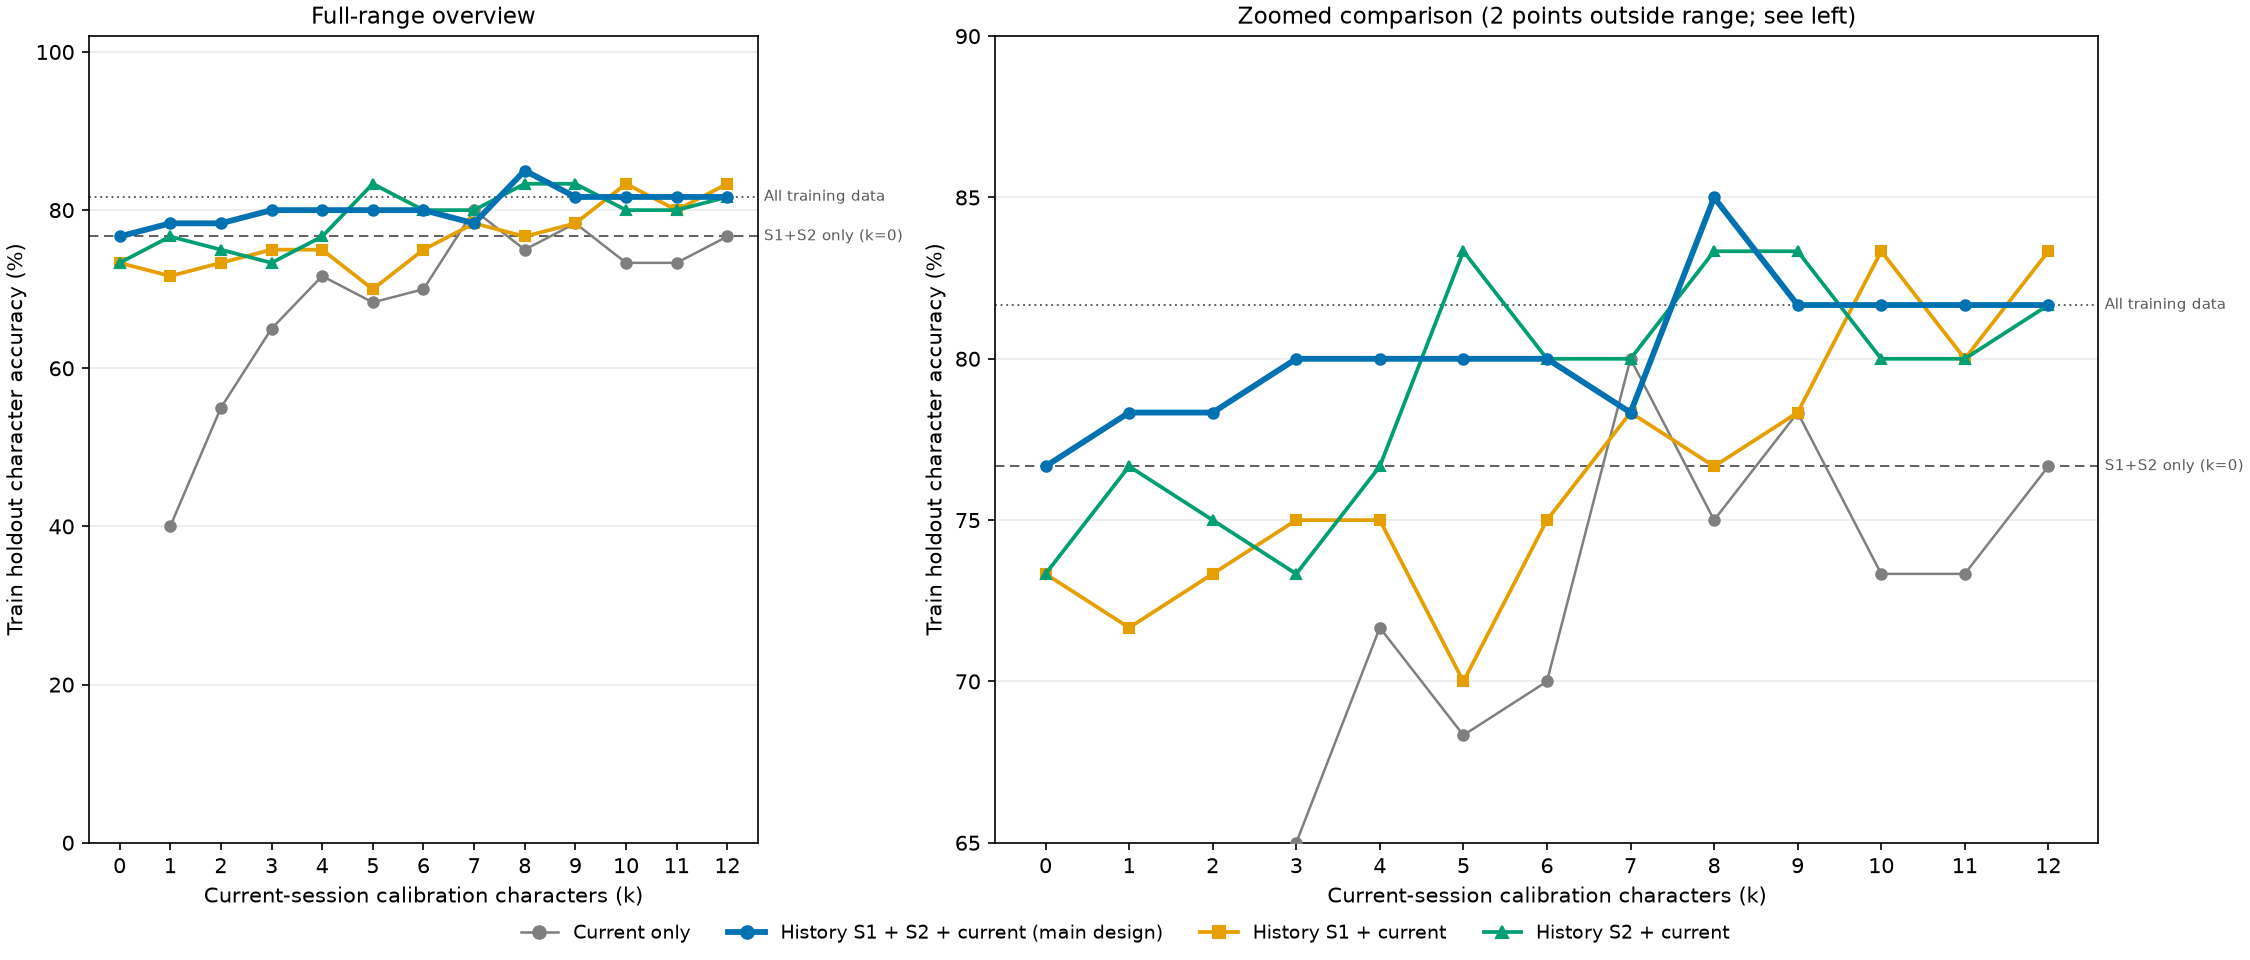

,scheme,k,correct_characters,validation_characters,pooled_accuracy
0,current_only,0,0,60,NaN
1,current_only,1,24,60,0.400000
2,current_only,2,33,60,0.550000
3,current_only,3,39,60,0.650000
4,current_only,4,43,60,0.716667
5,current_only,5,41,60,0.683333
6,current_only,6,42,60,0.700000
7,current_only,7,48,60,0.800000
8,current_only,8,45,60,0.750000
9,current_only,9,47,60,0.783333


In [5]:
display(Image(filename=str(OUT / 'character_accuracy_small_multiples.png')))
display(Image(filename=str(OUT / 'character_accuracy_curves.png')))
display(overall[['scheme', 'k', 'correct_characters', 'validation_characters', 'pooled_accuracy']])


## EEGNet 的停止点：使用 flash 级指标

当前仓库尚无 EEGNet 网络与训练循环，以上结果都是 SWLDA。`src/bigp3bci_flash_early_stopping.py` 同时提供 `FlashAUCEarlyStopping`（越大越好）与 `FlashLogLossEarlyStopping`（类别加权 log-loss，越小越好）。接入 EEGNet 前固定一种 checkpoint 选择规则；建议用加权 log-loss 选停止点，同时记录 AUC，不根据验证结果临时切换规则。字符准确率不参与选择；评估时需 `model.eval()` 并关闭梯度。

```python
stopper = FlashLogLossEarlyStopping(patience=15)
# 在真实 EEGNet 训练循环中：
# decision = stopper.update(validation_flash_labels, validation_positive_probabilities, epoch)
# if decision['improved']:
#     best_state = copy.deepcopy(model.state_dict())
# if decision['should_stop']:
#     break
# 训练结束后：model.load_state_dict(best_state)
```

若 EEGNet 训练本身也要加权，可用 `bigp3bci_probability.binary_class_weights(training_labels)` 得到 `N/(2N_class)` 的训练权重，仅从该模型预算内的训练标签计算。评价加权本身不会改变 SWLDA 拟合或纠正模型偏向。此处 patience 是接口默认值，没有根据本次验证结果调优；本 notebook 不启动 EEGNet 训练。


## 复现

运行 `python scripts/run_swlda_calibration_budget.py`；已有输出时需用 `--output` 指定新目录，以免覆盖结果。配置为 `configs/swlda_calibration_budget.json`。重建本报告：`python scripts/build_swlda_budget_notebook.py`。

`flash_predictions.csv` 保存每个模型的逐 flash 标签、分数及保留标记；`subject_results.csv` 保存逐被试 AUC；`overall_results.csv` 保存宏平均曲线。`character_roles.csv`、`training_character_membership.csv`、`fixed_validation_characters.csv` 和 `budget_leakage_audit.csv` 可核查划分与预算。验证集已用于开发，不应再称为独立最终测试。

补算概率层和加权 log-loss：`python scripts/add_weighted_logloss.py`，结果在 `weighted_logloss/`，包括逐 flash 概率、逐模型校准参数与交叉拟合方式。新的完整实验会自动执行此步骤；已有输出不会覆盖。
